# Modelling

Recommendation System, compare two retrieval methods:
- TF-IDF
- Vector cosine similarity

## Retrieval Setup

### 1. Read Data

Load the cases from `cleaning2.ipynb` and all tweets from `cleaned_df.pkl`.

RQ3: customer asks a new question -> find similar past cases -> show how support handled them.

A new question is the start of a conversation, so we only keep conversation starts in the library. Tweets like "still waiting" mean nothing without context. They still show up later, when we print the whole conversation of a case.

Every case is a customer tweet. We keep it if:
- `is_first_tweet == True`: it does not reply to another tweet (conversation start).
- It is also the customer's earliest tweet in the data. Some customers follow up by sending a new tweet, not a reply, e.g. "Just to be clear.. I have been home ALL day!". This is a conversation start but not a new question.

Cases that pass both are called first questions below.

Limit: the data starts on Oct 4. If a customer asks another unrelated question later, it is removed too.

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the cases and all tweets (tweets are used to find each customer's earliest tweet and full conversations)
cases = pd.read_pickle("../data/cases.pkl")
tweets = pd.read_pickle("../data/cleaned_df.pkl")
# Turn the time text into UTC datetime
tweets["created_at"] = pd.to_datetime(tweets["created_at"], format="%a %b %d %H:%M:%S %z %Y", utc=True)
print("All cases:", cases.shape[0])
# Keep conversation starts: customer tweets that do not reply to another tweet
cases = cases[cases["is_first_tweet"]].copy()
print("Conversation starts (customer tweets that are not replies):", cases.shape[0])

All cases: 209868
Conversation starts (customer tweets that are not replies): 127617


First questions (also the customer's earliest tweet): 110816


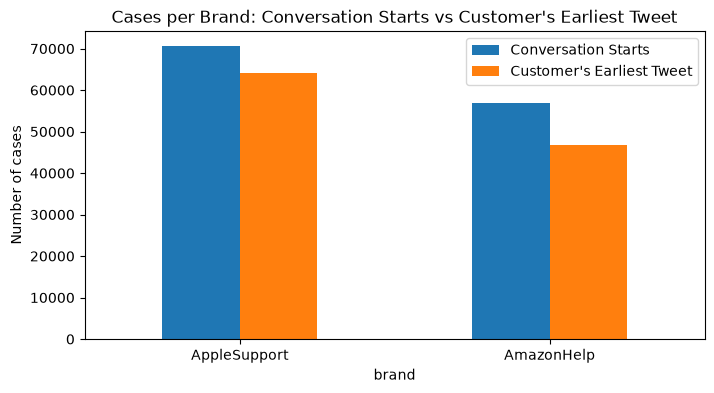

,Conversation Starts,Customer's Earliest Tweet
brand,,
AppleSupport,70701,64031
AmazonHelp,56916,46785


In [58]:
before = cases["brand"].value_counts()
# Find each customer's earliest tweet time, keep the case only if it is that tweet
customer_first_time = tweets[tweets["inbound"] == True].groupby("author_id")["created_at"].min()
cases = cases[cases["created_at"] == cases["customer_id"].map(customer_first_time)].copy()
print("First questions (also the customer's earliest tweet):", cases.shape[0])

# Compare the number of cases per brand before and after
brand_counts = pd.DataFrame({"Conversation Starts": before, "Customer's Earliest Tweet": cases["brand"].value_counts()})
brand_counts.plot(kind="bar", figsize=(8, 4), rot=0)
plt.ylabel("Number of cases")
plt.title("Cases per Brand: Conversation Starts vs Customer's Earliest Tweet")
plt.show()
brand_counts

### 2. Clean Text

New column `clean_text` is used for retrieval. `customer_text` is kept for display.

- `&amp;`, `&lt;`, `&gt;` -> `&`, `<`, `>`
- Remove `@` mentions and links, they do not describe the problem.
- Lowercase, join extra spaces.
- Punctuation, stop words and emojis are kept, since the embedding model works better on full sentences.

Texts with 3 words or fewer (like "fix this") are removed. They do not tell what the problem is.

In [59]:
# Turn HTML entities back into symbols
cases["clean_text"] = cases["customer_text"].str.replace("&amp;", "&").str.replace("&lt;", "<").str.replace("&gt;", ">")
# Remove @ mentions and links
cases["clean_text"] = cases["clean_text"].str.replace(r"@\w+", " ", regex=True).str.replace(r"https?://\S+", " ", regex=True)
# Lowercase and join extra spaces
cases["clean_text"] = cases["clean_text"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
cases[["customer_text", "clean_text"]].head()

,customer_text,clean_text
2,Apple Podcast is not played continuously on #iOS11 Is there a solution to this problem? @AppleSupport,apple podcast is not played continuously on #ios11 is there a solution to this problem?
5,@AppleSupport since I updated to the most current update the bar which shows how much you’ve listened to doesn’t move https://t.co/VUYr3hkWo0,since i updated to the most current update the bar which shows how much you’ve listened to doesn’t move
6,"@AppleSupport my iPhone used to work fine with my BMW iDrive. After ios11, it won’t work (music and texts)! Please help!","my iphone used to work fine with my bmw idrive. after ios11, it won’t work (music and texts)! please help!"
7,@AppleSupport will there be a fix for the poor #batterylife after update #iOS11 my phone has to be charged several times a day after #SE,will there be a fix for the poor #batterylife after update #ios11 my phone has to be charged several times a day after #se
8,@AppleSupport song previews aren’t playing on ITunes Store on my computer or iPhone. They just buffer forever and nothing happens.,song previews aren’t playing on itunes store on my computer or iphone. they just buffer forever and nothing happens.


In [60]:
# Count words and remove texts with 3 words or fewer
cases["word_count"] = cases["clean_text"].str.split().str.len()
print("Cases before removing short texts:", cases.shape[0])
cases = cases[cases["word_count"] > 3].copy()
print("Cases after removing short texts:", cases.shape[0])

Cases before removing short texts: 110816
Cases after removing short texts: 110022


### 3. Split Data

Split by time: past cases -> answer new questions.

- `history`: before Nov 27, 2017. The library we search in.
- `query`: Nov 27 to Dec 3, 2017 (last 7 days). The new questions.

A query cannot find itself in the library. The history set covers the iOS bug and Black Friday periods. Nov 27 is Cyber Monday, so the query set has a few more Amazon tweets.

We only search within the same brand as the query.

In [61]:
# The last 7 days are new questions (query), the rest is the library (history)
cases["set"] = np.where(cases["created_at"] >= "2017-11-27", "query", "history")
pd.DataFrame({"Number of Cases": cases.groupby(["set", "brand"]).size()})

Number of Cases
set     brand                        
history AmazonHelp              39162
        AppleSupport            58169
query   AmazonHelp               7372
        AppleSupport             5319

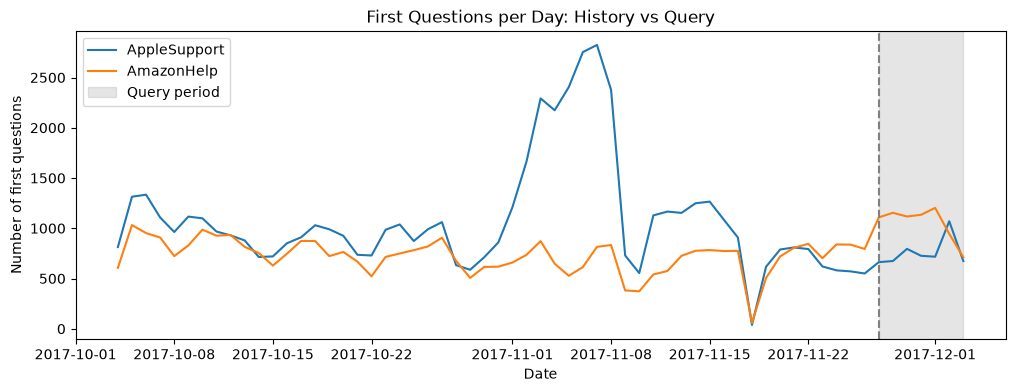

In [62]:
# First questions per day for each brand, with the query period shaded
day_counts = cases.groupby([cases["created_at"].dt.date, "brand"]).size().unstack()
plt.figure(figsize=(12, 4))
plt.plot(day_counts.index, day_counts["AppleSupport"], label="AppleSupport")
plt.plot(day_counts.index, day_counts["AmazonHelp"], label="AmazonHelp")
plt.axvline(pd.Timestamp("2017-11-27"), color="gray", linestyle="--")
plt.axvspan(pd.Timestamp("2017-11-27"), pd.Timestamp("2017-12-03"), color="gray", alpha=0.2, label="Query period")
plt.xlabel("Date")
plt.ylabel("Number of first questions")
plt.title("First Questions per Day: History vs Query")
plt.legend()
plt.show()

### 4. Method A: TF-IDF

TF-IDF turns a tweet into a vector of word weights. A word gets more weight if it is in this tweet but rare in the history set. So words like "battery" or "refund" matter more than common words.

- Fit on the history set only, then transform the queries.
- `stop_words="english"`: drop words like "the", "my".
- `min_df=2`: drop words that appear only once (typos, order numbers).
- The vectors have length 1, so the product of two vectors is the cosine similarity.

First look at the top 5 matches of one example query and their conversations, then the best-match score of 1,000 sample queries.

`get_chain(case_id)`: start from the first tweet -> keep adding tweets that reply to the chain -> sort by time. Used again in Section 5.

In [63]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Split into history and query
history = cases[cases["set"] == "history"].reset_index(drop=True)
query = cases[cases["set"] == "query"].reset_index(drop=True)
# Fit TF-IDF on history only, then transform the queries
tfidf = TfidfVectorizer(stop_words="english", min_df=2)
history_tfidf = tfidf.fit_transform(history["clean_text"])
query_tfidf = tfidf.transform(query["clean_text"])
print("Vocabulary size:", len(tfidf.vocabulary_))
print("History matrix:", history_tfidf.shape)
print("Query matrix:", query_tfidf.shape)

Vocabulary size: 14450
History matrix: (97331, 14450)
Query matrix: (12691, 14450)


In [64]:
pd.set_option("display.max_colwidth", None)
# Pick one example query
example = query.sample(1, random_state=1007).index[0]
print("Brand:", query.loc[example, "brand"])
print("Query:", query.loc[example, "customer_text"])

# Cosine similarity with every history case; other brand gets -1 so it is never picked
scores = (history_tfidf @ query_tfidf[example].T).toarray().ravel()
scores[(history["brand"] != query.loc[example, "brand"]).to_numpy()] = -1
# Index of the 5 highest scores
top = np.argsort(scores)[::-1][:5]
pd.DataFrame({"Score": scores[top], "Case ID": history.loc[top, "case_id"], "History Tweet": history.loc[top, "customer_text"]})

Brand: AmazonHelp
Query: @116090 @amazonhelp Well, 2 weeks of waiting and no package. I've called both the shipping company and your help line, both have been unable to do anything and refer me to the other. PLEASE stop using #intelcom!!!


,Score,Case ID,History Tweet
84918,0.321978,2611579,"@AmazonHelp Placed an order for 2 day shipping (prime member) and the items have been ""out for delivery"" in the wrong city for 3 days. Please stop using Intelcom for deliveries."
45833,0.317164,2606680,@AmazonHelp Can you stop using Intelcom for your Canadian Prime deliveries? They're late and I've received no tracking information.
39690,0.306331,1279910,I’m sick of Amazon I’ve been waiting on my package for 2 weeks it better be here today
90183,0.301404,2799329,@116090 @AmazonHelp stop shipping with Intelcom. Turns into an insane hassle with no possible resolutions. Ridiculous. Never had an issue with delivery until Intelcom was assigned to deliver things.
60593,0.288863,1640913,"@AmazonHelp Will be dumping our Prime membership until you stop using Intelcom - have had 1 successful delivery, many lost pacakges"


In [65]:
# Collect a case and all tweets that reply to it (directly or later in the chain)
def get_chain(case_id):
    chain_ids = [case_id]
    while True:
        new_ids = tweets.loc[tweets["in_response_to_tweet_id"].isin(chain_ids) & ~tweets["tweet_id"].isin(chain_ids), "tweet_id"].tolist()
        if len(new_ids) == 0:
            break
        chain_ids = chain_ids + new_ids
    # Sort the conversation by time
    chain = tweets[tweets["tweet_id"].isin(chain_ids)].sort_values("created_at")
    return pd.DataFrame({"Time": chain["created_at"].dt.strftime("%Y-%m-%d %H:%M"), "Author": np.where(chain["inbound"], "Customer", chain["author_id"]), "Text": chain["text"]})

# Show the full conversation of each top-5 match
for rank, i in enumerate(top):
    print(f"Match {rank + 1}, score {scores[i]:.3f}")
    display(get_chain(history.loc[i, "case_id"]))

Match 1, score 0.322


,Time,Author,Text
2442289,2017-11-17 11:56,Customer,"@AmazonHelp Placed an order for 2 day shipping (prime member) and the items have been ""out for delivery"" in the wrong city for 3 days. Please stop using Intelcom for deliveries."
2442288,2017-11-17 12:06,AmazonHelp,@738467 I am very sorry to hear this David. Can I ask for you to reach out to us through the link below so we can see what options we have for you: https://t.co/hApLpMlfHN. ^GA


Match 2, score 0.317


,Time,Author,Text
2437477,2017-10-30 21:00,Customer,@AmazonHelp Can you stop using Intelcom for your Canadian Prime deliveries? They're late and I've received no tracking information.
2437471,2017-10-30 21:04,AmazonHelp,@737428 I'm sorry for the poor delivery experiences! Have we missed a recent delivery for an order you placed? ^ME
2437472,2017-10-30 21:07,Customer,"@AmazonHelp A day late on delivery, about to be 2. No up to date tracking info. No package. I'm wondering why you continue to use this courrier"
2437473,2017-10-30 21:25,AmazonHelp,"@737428 If you have a moment, please contact us directly by phone or chat so we can look into this with you: https://t.co/Q7Ftz6nj80 ^LH"
2437474,2017-10-30 21:48,Customer,@AmazonHelp I spoke to someone on the phone. I was given a promo code but it still doesn't really fix the underlying problem with Intelcom itself.
2437475,2017-10-30 23:36,AmazonHelp,@737428 I understand the frustration with a late order! Did the agent mention sending your feedback to our transportation team? ^TN
2437476,2017-10-30 23:39,Customer,@AmazonHelp Yeah she did. Whether or not they'll actually do anything with the complaint is anyone's guess.


Match 3, score 0.306


,Time,Author,Text
1158697,2017-10-26 16:37,Customer,I’m sick of Amazon I’ve been waiting on my package for 2 weeks it better be here today
1158696,2017-10-26 16:45,AmazonHelp,@419470 I'm sorry to hear we've let you down! Have we missed the delivery date shown in confirmation e-mail? What is the status? ^FR


Match 4, score 0.301


,Time,Author,Text
2626976,2017-11-21 23:44,Customer,@116090 @AmazonHelp stop shipping with Intelcom. Turns into an insane hassle with no possible resolutions. Ridiculous. Never had an issue with delivery until Intelcom was assigned to deliver things.
2626975,2017-11-21 23:48,AmazonHelp,"@781015 I'm so sorry to hear this. If you have a moment, please reach us here: https://t.co/Q7Ftz6ETZy so we can submit a carrier's feedback on your behalf. ^LH"


Match 5, score 0.289


,Time,Author,Text
1494601,2017-11-05 23:24,Customer,"@AmazonHelp Will be dumping our Prime membership until you stop using Intelcom - have had 1 successful delivery, many lost pacakges"
1494599,2017-11-05 23:55,AmazonHelp,@501652 I'm sorry to hear this! Are you currently waiting on the delivery of a late package? ^BH
1494600,2017-11-06 00:00,Customer,"@AmazonHelp Item showing as delivered and was refunded already. But this is the 4th/5th time that Intelcom has ""delivered"" an item that never arrived"


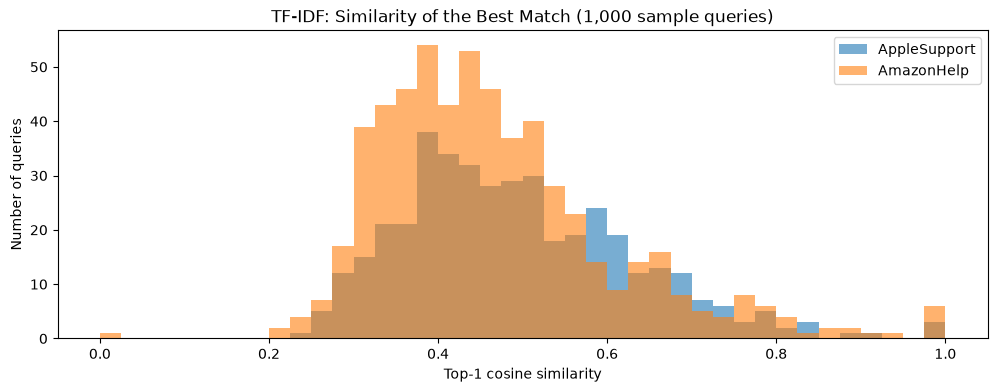

,count,mean,std,min,25%,50%,75%,max
brand,,,,,,,,
AmazonHelp,584.0,0.467082,0.141206,0.000000,0.367797,0.441375,0.530206,1.0
AppleSupport,416.0,0.496510,0.139874,0.229057,0.394541,0.476872,0.580237,1.0


In [66]:
# For 1,000 sample queries, record the best score within the same brand
sample = query.sample(1000, random_state=1007)
top1 = []
for i in sample.index:
    scores = (history_tfidf @ query_tfidf[i].T).toarray().ravel()
    top1.append(scores[(history["brand"] == query.loc[i, "brand"]).to_numpy()].max())
sample["tfidf_top1"] = top1

# Histogram of the best score for each brand
plt.figure(figsize=(12, 4))
plt.hist(sample.loc[sample["brand"] == "AppleSupport", "tfidf_top1"], bins=np.linspace(0, 1, 41), alpha=0.6, label="AppleSupport")
plt.hist(sample.loc[sample["brand"] == "AmazonHelp", "tfidf_top1"], bins=np.linspace(0, 1, 41), alpha=0.6, label="AmazonHelp")
plt.xlabel("Top-1 cosine similarity")
plt.ylabel("Number of queries")
plt.title("TF-IDF: Similarity of the Best Match (1,000 sample queries)")
plt.legend()
plt.show()
sample.groupby("brand")["tfidf_top1"].describe()

### 5. Method B: Embedding

An embedding model turns a tweet into a vector of its meaning, not only its words. "package never arrived" and "didn't receive my order" share no words, so TF-IDF cannot link them, but their embeddings are close.

- Model: `all-MiniLM-L6-v2` (sentence-transformers), 384 numbers for each tweet.
- Input is the same `clean_text` as TF-IDF, to keep the comparison fair.
- Encoding takes a few minutes on CPU, so the vectors are saved in `../data/*.npy`. Delete these files if the steps above change.

Similarity is computed with NumPy:
- Normalize: divide each vector by its length (`np.linalg.norm`). The product of two length-1 vectors is the cosine similarity. The model output already has length 1, the check below confirms it.
- One query: `history_emb @ query_vector` gives the scores of all history cases.
- Many queries: one matrix product for each brand, then `.max(axis=1)` to get the best score of each query. No loop over queries.

Same example query and same 1,000 sample queries as Section 4. The scores of the two methods are not on the same scale, so they are not compared here. See Section 6.

In [67]:
import os
import time
from sentence_transformers import SentenceTransformer

# Encode once and save; later runs load the saved arrays
if os.path.exists("../data/history_emb.npy") and os.path.exists("../data/query_emb.npy"):
    history_emb = np.load("../data/history_emb.npy")
    query_emb = np.load("../data/query_emb.npy")
else:
    model = SentenceTransformer("all-MiniLM-L6-v2")
    start = time.time()
    history_emb = model.encode(history["clean_text"].tolist(), batch_size=256, show_progress_bar=True)
    query_emb = model.encode(query["clean_text"].tolist(), batch_size=256, show_progress_bar=True)
    print(f"Encoding time: {time.time() - start:.0f} seconds")
    np.save("../data/history_emb.npy", history_emb)
    np.save("../data/query_emb.npy", query_emb)

# Check the saved arrays still match the current data
print("Rows match history and query:", history_emb.shape[0] == len(history) and query_emb.shape[0] == len(query))

Rows match history and query: True


In [68]:
# Length of each vector (one number per row)
history_norm = np.linalg.norm(history_emb, axis=1, keepdims=True)
query_norm = np.linalg.norm(query_emb, axis=1, keepdims=True)
print("Vector lengths before normalizing (first 5):", history_norm[:5].ravel().round(3))

# Divide each row by its own length (broadcasting), so every vector has length 1
history_emb = history_emb / history_norm
query_emb = query_emb / query_norm
print("All lengths are 1:", np.allclose(np.linalg.norm(history_emb, axis=1), 1) and np.allclose(np.linalg.norm(query_emb, axis=1), 1))
print("History embeddings:", history_emb.shape, history_emb.dtype, f"{history_emb.nbytes / 1e6:.0f} MB")
print("Query embeddings:", query_emb.shape, query_emb.dtype, f"{query_emb.nbytes / 1e6:.0f} MB")

Vector lengths before normalizing (first 5): [1. 1. 1. 1. 1.]
All lengths are 1: True
History embeddings: (97331, 384) float32 150 MB
Query embeddings: (12691, 384) float32 19 MB


In [69]:
# Same example query as Section 4: dot product with every history vector
print("Query:", query.loc[example, "customer_text"])
emb_scores = history_emb @ query_emb[example]

# Other brand gets -1 so it is never picked, then take the 5 highest scores
same_brand = (history["brand"] == query.loc[example, "brand"]).to_numpy()
emb_scores[~same_brand] = -1
emb_top = np.argsort(emb_scores)[::-1][:5]
pd.DataFrame({"Score": emb_scores[emb_top], "Case ID": history.loc[emb_top, "case_id"], "History Tweet": history.loc[emb_top, "customer_text"]})

Query: @116090 @amazonhelp Well, 2 weeks of waiting and no package. I've called both the shipping company and your help line, both have been unable to do anything and refer me to the other. PLEASE stop using #intelcom!!!


,Score,Case ID,History Tweet
88692,0.798062,2753577,Is there any way to get something shipped from @116090 without using #intelcom? Still waiting for the 1day shipping I ordered on Thursday and their site gives no updates and no way to contact people on the phone...
71973,0.790825,2205311,Hi @116090. Please stop sending packages with *Intelcom express*. They failed to deliver your package and followed it up with terrible customer service :(.
84918,0.719627,2611579,"@AmazonHelp Placed an order for 2 day shipping (prime member) and the items have been ""out for delivery"" in the wrong city for 3 days. Please stop using Intelcom for deliveries."
90183,0.675058,2799329,@116090 @AmazonHelp stop shipping with Intelcom. Turns into an insane hassle with no possible resolutions. Ridiculous. Never had an issue with delivery until Intelcom was assigned to deliver things.
89921,0.668758,2792004,@AmazonHelp My package I ordered was estimated to be delivered Nov 9 2017 - Nov 11 2017. It's still not here! Shipping courier is Intelcom but my tracking number doesn't go through! Help!


In [70]:
# Show the full conversation of each top-5 match
for rank, i in enumerate(emb_top):
    print(f"Match {rank + 1}, score {emb_scores[i]:.3f}")
    display(get_chain(history.loc[i, "case_id"]))

Match 1, score 0.798


,Time,Author,Text
2582429,2017-11-21 01:43,Customer,Is there any way to get something shipped from @116090 without using #intelcom? Still waiting for the 1day shipping I ordered on Thursday and their site gives no updates and no way to contact people on the phone...
2582427,2017-11-21 01:47,AmazonHelp,"@770774 I'm very sorry you haven't received your order. Whenever you have the time, give us a shout here: https://t.co/Q7Ftz6ETZy We'd be happy to assist with your order in real-time. ^SK"
2582428,2017-11-21 01:59,Customer,"@AmazonHelp I've been in contact with you guys twice already. You guys have been as helpful as you can be, it's the courier that you use that isn't. You cannot get a hold of them and their tracking system doesn't work."


Match 2, score 0.791


,Time,Author,Text
2046618,2017-11-09 22:41,Customer,Hi @116090. Please stop sending packages with *Intelcom express*. They failed to deliver your package and followed it up with terrible customer service :(.
2046617,2017-11-09 22:44,AmazonHelp,"@644809 I'm so sorry to hear this, Ash! We like our customers to have a great experience with us, and it seems we've let you down! Without posting personal account information, tell us more about your situation.\n-Anita"


Match 3, score 0.720


,Time,Author,Text
2442289,2017-11-17 11:56,Customer,"@AmazonHelp Placed an order for 2 day shipping (prime member) and the items have been ""out for delivery"" in the wrong city for 3 days. Please stop using Intelcom for deliveries."
2442288,2017-11-17 12:06,AmazonHelp,@738467 I am very sorry to hear this David. Can I ask for you to reach out to us through the link below so we can see what options we have for you: https://t.co/hApLpMlfHN. ^GA


Match 4, score 0.675


,Time,Author,Text
2626976,2017-11-21 23:44,Customer,@116090 @AmazonHelp stop shipping with Intelcom. Turns into an insane hassle with no possible resolutions. Ridiculous. Never had an issue with delivery until Intelcom was assigned to deliver things.
2626975,2017-11-21 23:48,AmazonHelp,"@781015 I'm so sorry to hear this. If you have a moment, please reach us here: https://t.co/Q7Ftz6ETZy so we can submit a carrier's feedback on your behalf. ^LH"


Match 5, score 0.669


,Time,Author,Text
2619689,2017-11-21 20:30,Customer,@AmazonHelp My package I ordered was estimated to be delivered Nov 9 2017 - Nov 11 2017. It's still not here! Shipping courier is Intelcom but my tracking number doesn't go through! Help!
2619688,2017-11-21 20:37,AmazonHelp,@779217 I'm sorry for the late package! We'd love to help! Let's take a look into this further in real-time. When you can please reach out to us through phone or chat here: https://t.co/JzP7hlA23B


AppleSupport similarity table: (416, 58169)
AmazonHelp similarity table: (584, 39162)
Time for 1,000 queries: 0.10 seconds


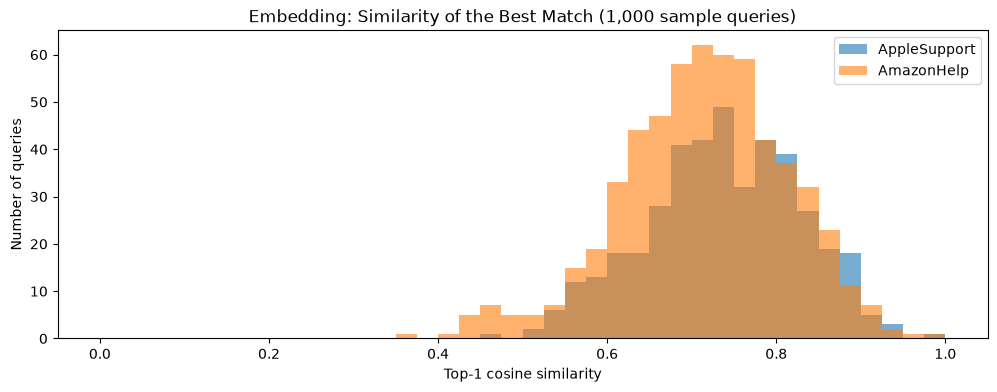

,25th Percentile,Median,75th Percentile
AppleSupport,0.681069,0.737897,0.804021
AmazonHelp,0.652070,0.719193,0.779103


In [71]:
# Same 1,000 sample queries as Section 4; one matrix product per brand instead of a loop over queries
start = time.time()
sample["emb_top1"] = 0.0
for brand in ["AppleSupport", "AmazonHelp"]:
    rows = (sample["brand"] == brand).to_numpy()
    brand_history = history_emb[(history["brand"] == brand).to_numpy()]
    sim = query_emb[sample.index[rows]] @ brand_history.T
    print(brand, "similarity table:", sim.shape)
    sample.loc[rows, "emb_top1"] = sim.max(axis=1)
print(f"Time for 1,000 queries: {time.time() - start:.2f} seconds")

# Histogram of the best score for each brand
plt.figure(figsize=(12, 4))
plt.hist(sample.loc[sample["brand"] == "AppleSupport", "emb_top1"], bins=np.linspace(0, 1, 41), alpha=0.6, label="AppleSupport")
plt.hist(sample.loc[sample["brand"] == "AmazonHelp", "emb_top1"], bins=np.linspace(0, 1, 41), alpha=0.6, label="AmazonHelp")
plt.xlabel("Top-1 cosine similarity")
plt.ylabel("Number of queries")
plt.title("Embedding: Similarity of the Best Match (1,000 sample queries)")
plt.legend()
plt.show()

# Median and quartiles of the best score with NumPy
brands = ["AppleSupport", "AmazonHelp"]
pd.DataFrame({
    "25th Percentile": [np.percentile(sample.loc[sample["brand"] == b, "emb_top1"], 25) for b in brands],
    "Median": [np.median(sample.loc[sample["brand"] == b, "emb_top1"]) for b in brands],
    "75th Percentile": [np.percentile(sample.loc[sample["brand"] == b, "emb_top1"], 75) for b in brands],
}, index=brands)

### 6. Evaluate

No label in the data says which cases are similar, so accuracy cannot be computed directly. We compare the two methods in indirect ways, with the same 1,000 sample queries.

#### 6.1 How Different Are the Results?

If the two methods return the same top 5, there is nothing to compare. So first count how many cases are in both top-5 lists for each query. 0: completely different. 5: identical.

In [72]:
# Top-5 history cases for each sample query: one row per query, one column per rank
k = 5
tfidf_top5 = np.zeros((len(sample), k), dtype=int)
emb_top5 = np.zeros((len(sample), k), dtype=int)

# TF-IDF: one query at a time
for n, i in enumerate(sample.index):
    scores = (history_tfidf @ query_tfidf[i].T).toarray().ravel()
    scores[(history["brand"] != query.loc[i, "brand"]).to_numpy()] = -1
    tfidf_top5[n] = np.argsort(scores)[::-1][:k]

# Embedding: one matrix product per brand, then sort each row from high to low
for brand in brands:
    rows = (sample["brand"] == brand).to_numpy()
    brand_index = np.where((history["brand"] == brand).to_numpy())[0]
    sim = query_emb[sample.index[rows]] @ history_emb[brand_index].T
    emb_top5[rows] = brand_index[np.argsort(sim, axis=1)[:, ::-1][:, :k]]

print("TF-IDF top-5 table:", tfidf_top5.shape)
print("Embedding top-5 table:", emb_top5.shape)

TF-IDF top-5 table: (1000, 5)
Embedding top-5 table: (1000, 5)


Average number of shared cases: 0.505


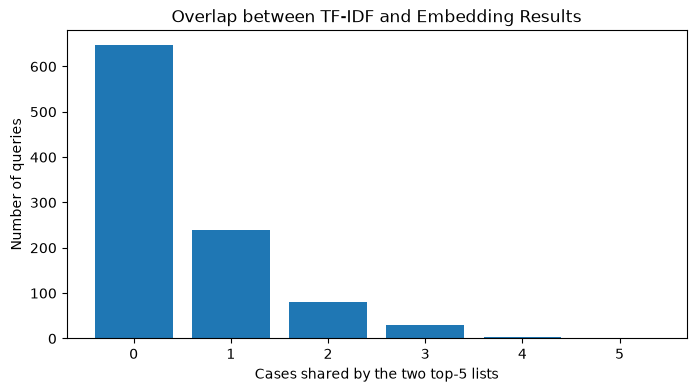

,Shared Cases,Number of Queries
0,0,647
1,1,239
2,2,81
3,3,29
4,4,3
5,5,1


In [73]:
# Count the cases that appear in both top-5 lists of each query
shared = np.array([len(np.intersect1d(tfidf_top5[n], emb_top5[n])) for n in range(len(sample))])
shared_counts = np.bincount(shared, minlength=k + 1)
print("Average number of shared cases:", shared.mean())

plt.figure(figsize=(8, 4))
plt.bar(np.arange(k + 1), shared_counts)
plt.xlabel("Cases shared by the two top-5 lists")
plt.ylabel("Number of queries")
plt.title("Overlap between TF-IDF and Embedding Results")
plt.show()
pd.DataFrame({"Shared Cases": np.arange(k + 1), "Number of Queries": shared_counts})

#### 6.2 Reply Similarity

Idea: similar problem -> similar reply from support. So we compare the real reply of a query with the replies of its top-5 matches. Higher similarity means better matches.

Two problems:
- Template replies like "send us a dm" make any two cases look similar. So a random baseline is added: 5 random cases from the same brand. A useful method should be clearly higher than random.
- The judge may be biased. Using embeddings to score replies may favor the embedding method, and using TF-IDF may favor TF-IDF. So both are used as judges. If a method wins under both judges, the result is more reliable.

Steps: clean replies (mentions, links, signatures like `^KH`) -> score with each judge -> mean over the 5 matches -> mean over the 1,000 queries.

For the embedding judge, only the replies we need are encoded (about 12,000). `np.searchsorted` and broadcasting compute the 1,000 x 5 similarities at once.

In [74]:
# Clean reply text: remove mentions, links and agent signatures like ^KH
history["reply_clean"] = history["reply_text"].str.replace(r"@\w+", " ", regex=True).str.replace(r"https?://\S+", " ", regex=True).str.replace(r"\^\w+", " ", regex=True)
history["reply_clean"] = history["reply_clean"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
sample["reply_clean"] = sample["reply_text"].str.replace(r"@\w+", " ", regex=True).str.replace(r"https?://\S+", " ", regex=True).str.replace(r"\^\w+", " ", regex=True)
sample["reply_clean"] = sample["reply_clean"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()

# How common are template replies?
print("History replies whose exact text is used more than once:", history["reply_clean"].duplicated(keep=False).sum(), "of", len(history))
pd.DataFrame({"Count": history["reply_clean"].value_counts().head(5)})

History replies whose exact text is used more than once: 19281 of 97331


,Count
reply_clean,
here’s what you can do to work around the issue until it’s fixed in a future software update:,4861
thanks for reaching out. we have a workaround for this here: dm us if you still need help.,575
thanks for reaching out. we're here to help. dm us so we can look into this further with you.,280
we're here to help. let's take this to dm so we can better assist you.,224
let's look into that. send us a dm and we'll go from there.,204


In [75]:
# Random baseline: 5 random history cases from the same brand for each query
rng = np.random.default_rng(1007)
random_top5 = np.zeros((len(sample), k), dtype=int)
for brand in brands:
    rows = (sample["brand"] == brand).to_numpy()
    brand_index = np.where((history["brand"] == brand).to_numpy())[0]
    random_top5[rows] = rng.choice(brand_index, size=(rows.sum(), k))
methods = {"Random": random_top5, "TF-IDF": tfidf_top5, "Embedding": emb_top5}

# Judge 1: TF-IDF similarity between the query's real reply and the replies of its 5 matches
reply_tfidf = TfidfVectorizer(stop_words="english", min_df=2)
history_reply_tfidf = reply_tfidf.fit_transform(history["reply_clean"])
sample_reply_tfidf = reply_tfidf.transform(sample["reply_clean"])
tfidf_judge = {}
for name, top5 in methods.items():
    tfidf_judge[name] = np.array([(history_reply_tfidf[top5[n]] @ sample_reply_tfidf[n].T).toarray().mean() for n in range(len(sample))])
    print("TF-IDF judge,", name, "mean reply similarity:", tfidf_judge[name].mean().round(3))

TF-IDF judge, Random mean reply similarity: 0.043
TF-IDF judge, TF-IDF mean reply similarity: 0.08
TF-IDF judge, Embedding mean reply similarity: 0.093


In [76]:
# Judge 2: embedding similarity; encode only the history replies that some method picked
needed = np.unique(np.concatenate([random_top5, tfidf_top5, emb_top5]))
model = SentenceTransformer("all-MiniLM-L6-v2")
needed_reply_emb = model.encode(history.loc[needed, "reply_clean"].tolist(), batch_size=256, show_progress_bar=True)
sample_reply_emb = model.encode(sample["reply_clean"].tolist(), batch_size=256, show_progress_bar=True)
needed_reply_emb = needed_reply_emb / np.linalg.norm(needed_reply_emb, axis=1, keepdims=True)
sample_reply_emb = sample_reply_emb / np.linalg.norm(sample_reply_emb, axis=1, keepdims=True)
print("Encoded history replies:", needed_reply_emb.shape)

emb_judge = {}
for name, top5 in methods.items():
    # Position of each matched case in the needed array, then a (1000, 5, 384) block of reply vectors
    matched = needed_reply_emb[np.searchsorted(needed, top5)]
    # Broadcasting: multiply each query reply with its 5 matched replies and sum over the 384 numbers
    sim = (matched * sample_reply_emb[:, np.newaxis, :]).sum(axis=2)
    emb_judge[name] = sim.mean(axis=1)
    print("Embedding judge,", name, "mean reply similarity:", emb_judge[name].mean().round(3))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/49 [00:00<?, ?it/s]

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Encoded history replies: (12539, 384)
Embedding judge, Random mean reply similarity: 0.293
Embedding judge, TF-IDF mean reply similarity: 0.369
Embedding judge, Embedding mean reply similarity: 0.398


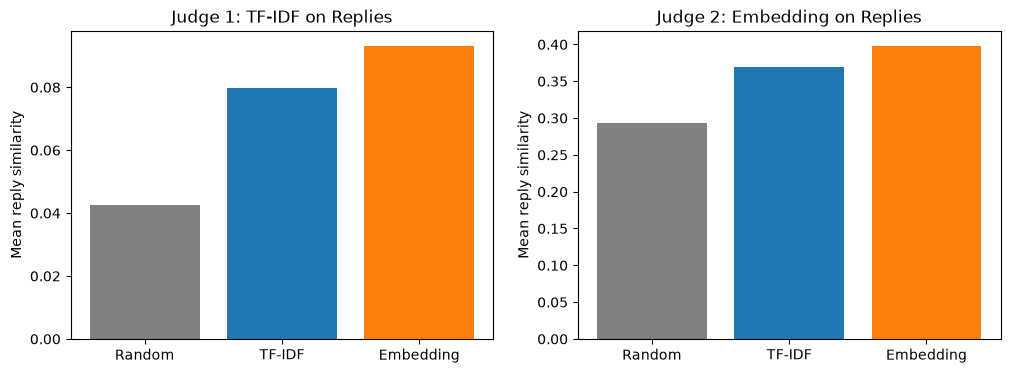

TF-IDF judge: Embedding wins 554 queries, TF-IDF wins 428 queries
Embedding judge: Embedding wins 600 queries, TF-IDF wins 399 queries


,TF-IDF Judge,Embedding Judge
Random,0.042543,0.293174
TF-IDF,0.079886,0.368697
Embedding,0.093247,0.398386


In [77]:
# Mean reply similarity of each method under each judge
summary = pd.DataFrame({
    "TF-IDF Judge": [tfidf_judge[name].mean() for name in methods],
    "Embedding Judge": [emb_judge[name].mean() for name in methods],
}, index=list(methods.keys()))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.bar(summary.index, summary["TF-IDF Judge"], color=["gray", "tab:blue", "tab:orange"])
plt.ylabel("Mean reply similarity")
plt.title("Judge 1: TF-IDF on Replies")
plt.subplot(1, 2, 2)
plt.bar(summary.index, summary["Embedding Judge"], color=["gray", "tab:blue", "tab:orange"])
plt.ylabel("Mean reply similarity")
plt.title("Judge 2: Embedding on Replies")
plt.show()

# Query by query: how often does one method beat the other?
print("TF-IDF judge: Embedding wins", (tfidf_judge["Embedding"] > tfidf_judge["TF-IDF"]).sum(), "queries, TF-IDF wins", (tfidf_judge["TF-IDF"] > tfidf_judge["Embedding"]).sum(), "queries")
print("Embedding judge: Embedding wins", (emb_judge["Embedding"] > emb_judge["TF-IDF"]).sum(), "queries, TF-IDF wins", (emb_judge["TF-IDF"] > emb_judge["Embedding"]).sum(), "queries")
summary

#### 6.3 Example Queries

The numbers in 6.2 are averages, so here we look at single queries.

- gap = reply similarity of embedding - reply similarity of TF-IDF (embedding judge). gap > 0: embedding did better on this query.
- The histogram shows the gap of all 1,000 queries.
- Then read the two queries with the largest gap in each direction, with the top 3 matches of both methods and their replies.

Mean gap: 0.03
Queries with a gap between -0.1 and 0.1: 657 of 1000


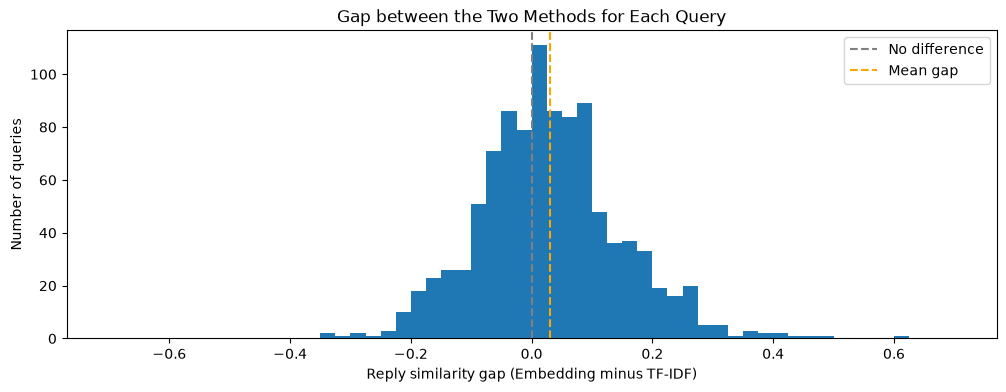

In [78]:
# Gap of each query: positive means the embedding method did better than TF-IDF
gap = emb_judge["Embedding"] - emb_judge["TF-IDF"]
print("Mean gap:", gap.mean().round(3))
print("Queries with a gap between -0.1 and 0.1:", ((gap > -0.1) & (gap < 0.1)).sum(), "of", len(gap))

plt.figure(figsize=(12, 4))
plt.hist(gap, bins=np.linspace(-0.7, 0.7, 57))
plt.axvline(0, color="gray", linestyle="--", label="No difference")
plt.axvline(gap.mean(), color="orange", linestyle="--", label="Mean gap")
plt.xlabel("Reply similarity gap (Embedding minus TF-IDF)")
plt.ylabel("Number of queries")
plt.title("Gap between the Two Methods for Each Query")
plt.legend()
plt.show()

In [79]:
# The two queries with the largest gap in each direction
examples = {"Embedding wins by the most": np.argmax(gap), "TF-IDF wins by the most": np.argmin(gap)}

for title, n in examples.items():
    print(f"{title} (gap {gap[n]:.3f})")
    print("Query:", sample.iloc[n]["customer_text"])
    print("Real reply:", sample.iloc[n]["reply_text"])
    # Top-3 matches of each method and the support reply each one got
    top3 = np.concatenate([tfidf_top5[n, :3], emb_top5[n, :3]])
    display(pd.DataFrame({"Method": ["TF-IDF"] * 3 + ["Embedding"] * 3, "Rank": [1, 2, 3] * 2, "History Tweet": history.loc[top3, "customer_text"].to_numpy(), "Reply": history.loc[top3, "reply_text"].to_numpy()}))

Embedding wins by the most (gap 0.624)
Query: @115850  when shall the next  Great Indian Sale begin??  Very much excited to shop  from this brilliant online shopping site.  Hoping to get more offers and discounts next time.
Real reply: @620757 We haven't made an announcement yet. Please stay tuned to our website. ^KA


,Method,Rank,History Tweet,Reply
0,TF-IDF,1,Amazon India is the worst shopping online site,@443827 That's quite a comment. Please let us know what went wrong so that we can look into it? ^BV
1,TF-IDF,2,"@115850 \nHi, is the cashback of Great indian Sale being delayed for everyone or just me?",@211368 We'd like to know more about this. Could you help us with the offer name/cash back page link? We'll look into it. ^HD
2,TF-IDF,3,Thanks @115850 for Great Indian Festival 🎆 🎇... HapPy shopping...,"@196039 Aww thank you, we appreciate the kind words and we're here to help if you need us :) ^VN"
3,Embedding,1,"Hello, what are the upcoming sales in November on Amazon India?",@688861 We haven't made any announcements yet. Stay tuned to Amazon.in where we highlight the latest offers. ^AS
4,Embedding,2,@AmazonHelp When will be the amazon black Friday sale in india??Any updates...,"@416535 We haven't announced any dates as of now, kindly stay tuned to our website for updates. ^RD"
5,Embedding,3,When #amazon festive #sale starting in india? #eagerly #AmazonIndia @AmazonHelp,@294042 We have not made any announcement on this yet. Please stay tuned. ^HK


TF-IDF wins by the most (gap -0.336)
Query: @AppleSupport  I'm having issues with iPhone 7, running 11.1.2. it has developed a bug where every 2mins the screen go black and a spinning wheel appear, after that it goes to the lock screen and wants my passcode. i've changed the date to 30Nov as a temp fix and it works.
Real reply: @245932 You're in the right place for help. Let’s make sure you have a backup, then follow the steps in this article, which includes updating to iOS version 11.2: https://t.co/Wc5MHFZb0p

If you have any questions, let us know.


,Method,Rank,History Tweet,Reply
0,TF-IDF,1,My sound working when it wants and when I’m on the phone my screen is black not to my lock screen @115858 FIX IT,@496180 DM us using the link below and let us know your iOS version from Settings &gt; General &gt; About &gt; Version. We're glad to assist. https://t.co/GDrqU22YpT
1,TF-IDF,2,"This new iOS 11 bug sucks. Log in to phone and see this spinning wheel, goes back to lock screen, then have to log in again to get it to work. Using PIN; not FaceID. @AppleSupport https://t.co/nUkPxw19Gp",@303338 We’re here to help. Please DM us the version of iOS 11 you’re using so we can better assist you. https://t.co/GDrqU22YpT
2,TF-IDF,3,@AppleSupport why do I keep getting this spinning wheel screen and then back to PIN unlock screen. Happens multiple times a day. 11.1.2. iPhone 7+ https://t.co/CJrwMfjpAx,"@279191 Thank you for reaching out. May we ask when you started to notice this? Was it after a recent iOS update? Also, have you noticed this more with certain apps DM us and let us know. https://t.co/GDrqU22YpT"
3,Embedding,1,"@AppleSupport why do I intermittently get a black screen w/ a spinning wheel after unlocking w/ passcode on #iphonex ? It happened w/fresh iPhone, I’ve restarted, latest iOS, still happening w/ reloaded backup. https://t.co/NU4oGzKnpj","@668391 We want your iPhone X to be working perfectly! Meet us in DM, tell us which country you're in, and we'll take a look there. https://t.co/GDrqU22YpT"
4,Embedding,2,@AppleSupport why do I keep getting this spinning wheel screen and then back to PIN unlock screen. Happens multiple times a day. 11.1.2. iPhone 7+ https://t.co/CJrwMfjpAx,"@279191 Thank you for reaching out. May we ask when you started to notice this? Was it after a recent iOS update? Also, have you noticed this more with certain apps DM us and let us know. https://t.co/GDrqU22YpT"
5,Embedding,3,"@AppleSupport Hi, have a weird issue with iPhone 7 running iOS 11.0.2. Can I DM you with the details?",@193307 Absolutely. Let us know what's going on in DM. https://t.co/GDrqU22YpT


#### 6.4 Summary

Results on the 1,000 sample queries:

- The two methods return different cases. On average only 0.5 of the 5 matches are shared, and 647 queries share nothing.
- Both are better than random under both judges. TF-IDF judge: random 0.043, TF-IDF 0.080, embedding 0.093. Embedding judge: 0.293, 0.369, 0.398.
- Embedding is a little better. It is higher under both judges and wins more queries (554 vs 428, 600 vs 399).
- But the difference is small. The mean gap is 0.03, and 657 queries have a gap between -0.1 and 0.1.

The two examples:

- Embedding wins: the customer asks when the next sale begins. TF-IDF matches tweets with the same words ("shopping", "Great Indian"), but they are a complaint, a cashback question and a thank-you. Embedding finds the same question asked in other words, and the replies are almost the same as the real reply.
- TF-IDF wins: a spinning wheel and lock screen bug. Both methods find the same problem and even share one match. TF-IDF only wins because the wording of the replies is closer. So winning on one query does not always mean better matches.

Limits:

- Reply similarity is an indirect measure. The same problem can get replies in different words, and about 20% of the history replies are reused templates.
- Only 1,000 queries from one week are tested.
- The matches are not checked by hand yet.

We use the embedding method in the prediction part. TF-IDF is kept as a baseline: no model to download, and it is good at rare names like "Intelcom".

### 7. Search Function for Prediction

Put the embedding method into one function for `prediction.ipynb`.

User input -> clean -> encode -> similar cases of the same brand.

- Library: the last week was kept out only for the evaluation. In real use it is also history, so history and query are stacked together with `pd.concat` (tables) and `np.vstack` (vectors).
- Saved files: `../data/search_cases.pkl` (cases) and `../data/search_emb.npy` (vectors). Rows are in the same order.
- `search(text, brand, k=5)`: returns the `k` most similar cases with score, case ID, customer tweet, first reply and waiting minutes.
- `get_chain(case_id)`: shows the full conversation of a match.

Tested with two made-up questions. The last plot shows the waiting time of the 20 most similar cases. How to turn it into a predicted waiting time is left to the prediction part.

In [80]:
# The evaluation is done, so the last week joins the library: stack tables and vectors in the same order
search_cases = pd.concat([history, query], ignore_index=True)
search_emb = np.vstack([history_emb, query_emb])
print("Library cases:", search_cases.shape[0])
print("Library embeddings:", search_emb.shape)
print("Rows match:", search_cases.shape[0] == search_emb.shape[0])

# Keep the columns needed for search and save both files for prediction.ipynb
search_cases = search_cases[["case_id", "brand", "customer_text", "reply_text", "created_at", "response_minutes"]]
search_cases.to_pickle("../data/search_cases.pkl")
np.save("../data/search_emb.npy", search_emb)

Library cases: 110022
Library embeddings: (110022, 384)
Rows match: True


In [81]:
def search(text, brand, k=5):
    # Clean the new question with the same rules as Section 2
    clean = pd.Series([text]).str.replace("&amp;", "&").str.replace("&lt;", "<").str.replace("&gt;", ">")
    clean = clean.str.replace(r"@\w+", " ", regex=True).str.replace(r"https?://\S+", " ", regex=True)
    clean = clean.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
    # Encode it and make the vector length 1
    vector = model.encode(clean.tolist())[0]
    vector = vector / np.linalg.norm(vector)
    # Cosine similarity with every library case; other brand gets -1 so it is never picked
    scores = search_emb @ vector
    scores[(search_cases["brand"] != brand).to_numpy()] = -1
    top = np.argsort(scores)[::-1][:k]
    return pd.DataFrame({
        "Score": scores[top],
        "Case ID": search_cases.loc[top, "case_id"].to_numpy(),
        "Customer Tweet": search_cases.loc[top, "customer_text"].to_numpy(),
        "First Reply": search_cases.loc[top, "reply_text"].to_numpy(),
        "Response Minutes": search_cases.loc[top, "response_minutes"].to_numpy(),
    })

In [82]:
# Try two made-up new questions, one for each brand
new_questions = [
    ("My package says delivered but I never received it", "AmazonHelp"),
    ("Battery drains very fast after updating to iOS 11", "AppleSupport"),
]
for text, brand in new_questions:
    print("New question:", text, f"({brand})")
    result = search(text, brand)
    display(result)
    print("Full conversation of the best match:")
    display(get_chain(result.loc[0, "Case ID"]))

New question: My package says delivered but I never received it (AmazonHelp)


,Score,Case ID,Customer Tweet,First Reply,Response Minutes
0,0.861001,1112103,Sos @115821 @AmazonHelp @118706 @123967 my package says delivered but it never got here https://t.co/U4aRe8cPbG,"@382462 Just in case, have you checked your mailbox? Please also try these steps and keep us posted: https://t.co/8W0piplqfc ^BH",10.133333
1,0.847082,842259,I never received my @115821 order and it says it was delivered yesterday @AmazonHelp,@320336 Sorry to hear you didn't receive your package! We would love to help. Let's try the steps here: https://t.co/X8TflYmLFV ^SH,44.150000
2,0.838711,2948178,@115821 Its says my package was delivered but it hasnt been,"@814234 I'm sorry you don't have your package, Hero! Please give these steps a try: https://t.co/GmDjuh55FG, and keep us updated on the outcome. ^WJ",6.383333
3,0.832715,1189461,Did not received my package @115850.,@399598 Could you please confirm if we have missed the mentioned time frame? 2/2 ^AH,17.800000
4,0.826213,2888208,@115821 I never received my package :/ says it was delivered. What do I do?,"@800865 I'm sorry for the trouble with delivery, Chloe! Have you tried these steps in regard to finding your package: https://t.co/7LYbk5TtST? Let us know! ^TG",12.050000


Full conversation of the best match:


,Time,Author,Text
1003609,2017-10-24 02:08,Customer,Sos @115821 @AmazonHelp @118706 @123967 my package says delivered but it never got here https://t.co/U4aRe8cPbG
1003606,2017-10-24 02:18,AmazonHelp,"@382462 Just in case, have you checked your mailbox? Please also try these steps and keep us posted: https://t.co/8W0piplqfc ^BH"
1003607,2017-10-24 02:19,Customer,@AmazonHelp I did check my mailbox and my neighbors porch just Incase it got delivered to the wrong house
1003608,2017-10-24 02:40,AmazonHelp,"@382462 Sorry you didn't get your package. Sometimes carriers accidentally scan early. If you don't see it by tomorrow, let us know!^EB"


New question: Battery drains very fast after updating to iOS 11 (AppleSupport)


,Score,Case ID,Customer Tweet,First Reply,Response Minutes
0,0.907320,2025149,@115858 @AppleSupport my battery is draining faster than ever on the new iOS 11.0 https://t.co/A72Hv7hsyQ,@598901 Let's see what we can find out! You’ll want to start by backing up and updating to iOS 11.1. DM us if the issue persists. https://t.co/GDrqU22YpT,294.066667
1,0.898212,2059764,"@AppleSupport Battery drains faster even after updating to iOS 11.0.2, needs a fix especially for the battery draining issue.",@609180 We know how vital the battery is. Please check out this article: https://t.co/TpjqFp3jxD \n\nDM us the results. https://t.co/GDrqU22YpT,522.083333
2,0.897160,2029103,@AppleSupport my battery is draining faster than ever on the new iOS 11.1,"@600050 That's not how we want an update to behave! Meet us in DM, tell us which country you're in and we'll take a look. https://t.co/GDrqU22YpT",179.333333
3,0.895723,1975916,facing faster battery drain issues after upgrading to ios 11.1 @AppleSupport @115858,"@585138 Hey there, we'd be happy to look into this with you. DM us and let us know which device this is happening on. We'll go from there. https://t.co/GDrqU22YpT",45.433333
4,0.895549,1097746,@AppleSupport what is the fix for the fast battery drain since I upgraded to IOS 11.0.3?,@379044 We'd love to help you with your iPhone battery. DM us and we'll continue there. https://t.co/GDrqU2kzhr,6.166667


Full conversation of the best match:


,Time,Author,Text
1868930,2017-11-06 11:05,Customer,@115858 @AppleSupport my battery is draining faster than ever on the new iOS 11.0 https://t.co/A72Hv7hsyQ
1868929,2017-11-06 15:59,AppleSupport,@598901 Let's see what we can find out! You’ll want to start by backing up and updating to iOS 11.1. DM us if the issue persists. https://t.co/GDrqU22YpT


Median waiting time of the 20 similar cases: 114.2 minutes
Median waiting time of all AppleSupport cases: 89.3 minutes


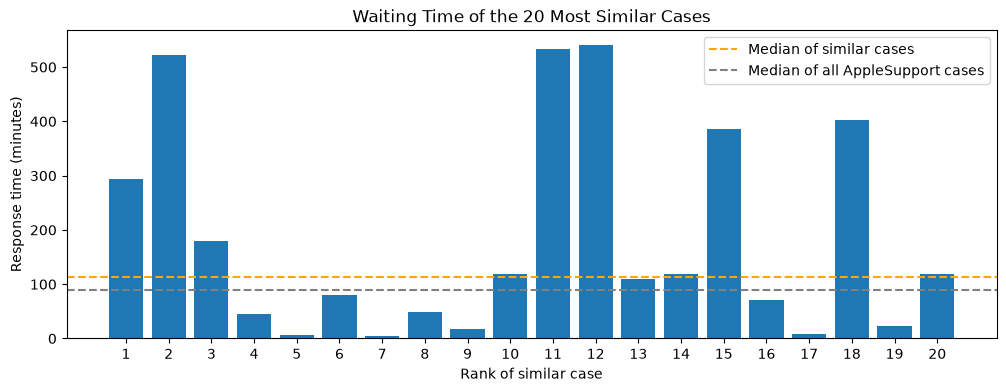

In [83]:
# Waiting time of the 20 most similar cases, compared with the median of all cases of the brand
similar = search("Battery drains very fast after updating to iOS 11", "AppleSupport", k=20)
brand_median = np.median(search_cases.loc[search_cases["brand"] == "AppleSupport", "response_minutes"])
similar_median = np.median(similar["Response Minutes"])
print("Median waiting time of the 20 similar cases:", similar_median.round(1), "minutes")
print("Median waiting time of all AppleSupport cases:", brand_median.round(1), "minutes")

plt.figure(figsize=(12, 4))
plt.bar(np.arange(1, 21), similar["Response Minutes"])
plt.axhline(similar_median, color="orange", linestyle="--", label="Median of similar cases")
plt.axhline(brand_median, color="gray", linestyle="--", label="Median of all AppleSupport cases")
plt.xticks(np.arange(1, 21))
plt.xlabel("Rank of similar case")
plt.ylabel("Response time (minutes)")
plt.title("Waiting Time of the 20 Most Similar Cases")
plt.legend()
plt.show()